# GSS-LSF (with ADAM and closed-form graph Fourier baseline)

This demonstration reproduce the published **fixed-random-input learnable spectral filter** (GSS-LSF).

The paper's parameterization is $\hat x_p = U_{p,k_p}\operatorname{diag}(\alpha_p) U_{p,k_p}^\top z$, where the vector $z$ is sampled once and fixed. Its spectral gains $\alpha_p$ are optimized by Adam against the observed mixture. Since the resulting linear parameterization spans the same truncated subspaces (if every projected coefficient of $z$ is nonzero), this also can be solved by the **same least-squares optimum** as mentioned in the paper. Finite-step optimization may differ.


In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import matplotlib.pyplot as plt
import torch

import numpy as np

from spectral_lsf.spectral import (
    build_graph,
    learnable_spectral_filters,
    closed_form_spectral,
    make_noisy_mixture,
    seed_everything,
    snr_db,
    spectral_grid_search,
)
from spectral_lsf.plotting import plot_separation

## Experiment configuration

In [2]:
# Choose the timestamp/row to reproduce an experiment.
ROW = 6000

# Original notebook settings.
SEED = 42
GRAPH_K = 5
NOISE_STD = 0.2

# Keep True for reproduction; use False for a non-oracle experiment.
USE_ORACLE_GRID_SEARCH = False
K_MIN = 2
K_MAX = 50

# Used only when USE_ORACLE_GRID_SEARCH = False.
K_TEMPERATURE = 5
K_PRESSURE = 5

## Load one preprocessed row

In [3]:
data = torch.load("sensor_data.pt", weights_only=True)

x_temperature = data["x_temperature"]
x_pressure = data["x_pressure"]

print("Temperature shape:", tuple(x_temperature.shape))
print("Pressure shape   :", tuple(x_pressure.shape))

Temperature shape: (14, 1)
Pressure shape   : (14, 1)


## Create the noisy mixture and the two source graphs

In [4]:
seed_everything(SEED)

mixed, noise = make_noisy_mixture(
    x_temperature,
    x_pressure,
    noise_std=NOISE_STD,
)

L_temperature = build_graph(x_temperature, k=GRAPH_K)
L_pressure = build_graph(x_pressure, k=GRAPH_K)

print(f"Noise std: {NOISE_STD}")
print("L_temperature:", tuple(L_temperature.shape))
print("L_pressure   :", tuple(L_pressure.shape))

Noise std: 0.2
L_temperature: (14, 14)
L_pressure   : (14, 14)


## Run the closed-form least-squares for GSS-LSF


In [5]:
if USE_ORACLE_GRID_SEARCH:
    result = spectral_grid_search(
        L_temperature,
        L_pressure,
        mixed,
        x_temperature,
        x_pressure,
        k_min=K_MIN,
        k_max=K_MAX,
    )
    x_temperature_hat = result.temperature
    x_pressure_hat = result.pressure
    k_temperature = result.k_temperature
    k_pressure = result.k_pressure
    snr_temperature = result.snr_temperature
    snr_pressure = result.snr_pressure
else:
    x_temperature_hat, x_pressure_hat = closed_form_spectral(
        L_temperature,
        L_pressure,
        mixed,
        K_TEMPERATURE,
        K_PRESSURE,
    )
    k_temperature = K_TEMPERATURE
    k_pressure = K_PRESSURE
    snr_temperature = snr_db(x_temperature.numpy(), x_temperature_hat.numpy())
    snr_pressure = snr_db(x_pressure.numpy(), x_pressure_hat.numpy())

average_snr = 0.5 * (snr_temperature + snr_pressure)

print("===== CLOSED-FORM BASELINE RESULTS =====")
print(f"k_temperature : {k_temperature}")
print(f"k_pressure    : {k_pressure}")
print(f"Temp SNR      : {snr_temperature:.2f} dB")
print(f"Pressure SNR  : {snr_pressure:.2f} dB")
print(f"Average SNR   : {average_snr:.2f} dB")

===== CLOSED-FORM BASELINE RESULTS =====
k_temperature : 5
k_pressure    : 5
Temp SNR      : 19.06 dB
Pressure SNR  : 19.70 dB
Average SNR   : 19.38 dB


## Visualize

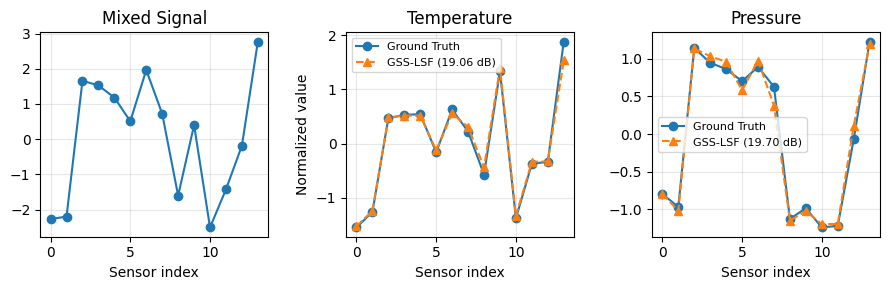

In [6]:
plot_separation(
    x_temperature.numpy(),
    x_pressure.numpy(),
    mixed.numpy(),
    x_temperature_hat.numpy(),
    x_pressure_hat.numpy(),
    snr_temperature=snr_temperature,
    snr_pressure=snr_pressure,
    save_path="spectral_lsf_result.pdf",
)
plt.show()

## Using Adam in Learnable spectral filters (GSS-LSF)

This method trains **only** spectral gains, with fixed graph Fourier bases and one fixed random input. The graph inputs used here were constructed from ground-truth sources, for illustration only. Training uses no true-source labels.


In [7]:
LSF_STEPS = 2500
LSF_LR = 0.05

lsf_result = learnable_spectral_filters(
    L_temperature, L_pressure, mixed,
    k1=k_temperature, k2=k_pressure,
    steps=LSF_STEPS, lr=LSF_LR, seed=SEED,
)
lsf_temperature = lsf_result.temperature
lsf_pressure = lsf_result.pressure
lsf_snr_temperature = snr_db(x_temperature.numpy(), lsf_temperature.numpy())
lsf_snr_pressure = snr_db(x_pressure.numpy(), lsf_pressure.numpy())

print(f"GSS-LSF: temperature = {lsf_snr_temperature:.3f} dB; pressure = {lsf_snr_pressure:.3f} dB")
print(f"Closed-form: temperature = {snr_temperature:.3f} dB; pressure = {snr_pressure:.3f} dB")
print(f"Final unsupervised mixture loss = {lsf_result.losses[-1]:.6g}")


GSS-LSF: temperature = 19.066 dB; pressure = 19.696 dB
Closed-form: temperature = 19.064 dB; pressure = 19.696 dB
Final unsupervised mixture loss = 0.0199386


## Comparison and diagnostics

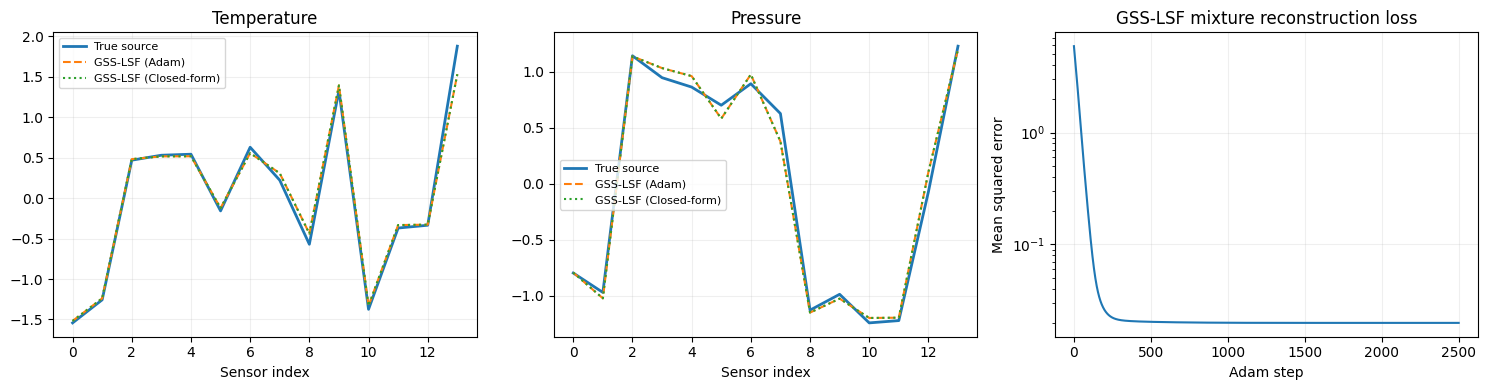

Comparison (SNR dB):
Method                Temperature     Pressure      Average
GSS-LSF (Closed-form)       19.064       19.696       19.380
GSS-LSF (Adam)             19.066       19.696       19.381


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = ["Temperature", "Pressure"]
for i, (truth, ls, cf) in enumerate([
    (x_temperature, lsf_temperature, x_temperature_hat),
    (x_pressure, lsf_pressure, x_pressure_hat),
]):
    axes[i].plot(truth.numpy().ravel(), label="True source", lw=2)
    axes[i].plot(ls.numpy().ravel(), label="GSS-LSF (Adam)", ls="--")
    axes[i].plot(cf.numpy().ravel(), label="GSS-LSF (Closed-form)", ls=":")
    axes[i].set_title(labels[i])
    axes[i].set_xlabel("Sensor index")
    axes[i].grid(alpha=0.2)
    axes[i].legend(fontsize=8)
axes[2].plot(lsf_result.losses)
axes[2].set_title("GSS-LSF mixture reconstruction loss")
axes[2].set_xlabel("Adam step")
axes[2].set_ylabel("Mean squared error")
axes[2].set_yscale("log")
axes[2].grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Comparison (SNR dB):")
print(f"{'Method':<20} {'Temperature':>12} {'Pressure':>12} {'Average':>12}")
print(f"{'GSS-LSF (Closed-form)':<20} {snr_temperature:12.3f} {snr_pressure:12.3f} {(snr_temperature + snr_pressure)/2:12.3f}")
print(f"{'GSS-LSF (Adam)':<20} {lsf_snr_temperature:12.3f} {lsf_snr_pressure:12.3f} {(lsf_snr_temperature + lsf_snr_pressure)/2:12.3f}")
